# 03 — A címkék ellenőrzése / Validating the labels

HU: Valódi címke hiányában öt bizonyítékot gyűjtünk arról, hogy a BERT-címkék megbízhatóak:

| # | Bizonyíték / Evidence | Mit mutat? / What does it show? |
|---|---|---|
| 1 | Eloszlások / Distributions | mennyire térnek el a források / how the sources differ |
| 2 | Egyezés (kappa) / Agreement | a három megközelítés konzisztenciája / consistency of the three |
| 3 | Vendégpontszám / Guest score | konvergens validitás / convergent validity |
| 4 | Mezőpróba, HRAST-teszt / Field test, HRAST test | független ellenőrzés / independent checks |
| 5 | **Kézi gold minta / Manual gold sample** | **közvetlen pontosság / direct accuracy** |

Ez a notebook CPU-n, helyben fut (a 02 mentett eredményeiből). / Runs locally on a CPU (from the saved outputs of 02).

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import label_validation as lv
from src import pipeline

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

data = dl.read_frame(pipeline.LABELLED).set_index("review_id")
data["score_cut_label"] = lv.score_cut_labels(data["score"])     # HU/EN: REFERENCE ONLY
approaches = lv.available_approaches(data)
SOURCES = {**{f"{a}": f"{a}_label" for a in approaches}, "final": "label_final",
           "score cut (reference)": "score_cut_label"}
print(f"{len(data):,} reviews | approaches: {approaches}")

20,000 reviews | approaches: ['A', 'B', 'C']


## 1. Eloszlások / Distributions

,negative,neutral,positive,n
A,0.0341,0.0381,0.9278,20000
B,0.0510,0.1744,0.7746,20000
C,0.0238,0.3478,0.6284,20000
final,0.0462,0.1744,0.7794,20000
score cut (reference),0.1289,0.2262,0.6450,20000


21:58:56 | INFO    | src.evaluation | Table saved: 03_label_distribution.csv
21:58:57 | INFO    | src.evaluation | Figure saved: 03_label_distribution.png


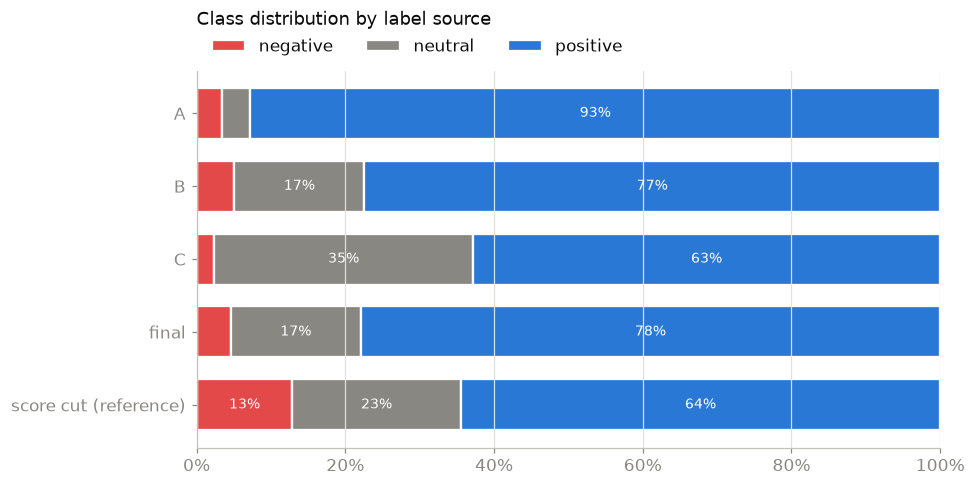

In [2]:
dist = lv.label_distribution(data, SOURCES)
display(dist)
ev.save_table(dist, "03_label_distribution")
lv.plot_label_distribution(dist, title="Class distribution by label source", save_as="03_label_distribution")
plt.show()

## 2. Egyezés a megközelítések között / Agreement between the approaches

HU: A (C) a saját tanítóvéleményein a tanárokat "visszamondja", ezért azokat kizárjuk (`comparison_mask`).
EN: On its own training reviews (C) "repeats" the teachers, so those are excluded (`comparison_mask`).

In [3]:
mask = lv.comparison_mask(data)
print(f"Rows used for agreement: {mask.sum():,} of {len(data):,}")
agreement = lv.pairwise_agreement(data[mask], SOURCES)
display(agreement)
ev.save_table(agreement, "03_pairwise_agreement")
fk = lv.fleiss_kappa(data[mask], [f"{a}_label" for a in approaches])
print(f"Fleiss' kappa ({', '.join(approaches)}): {fk:.3f}")

Rows used for agreement: 10,331 of 20,000


,n,agreement,cohen_kappa,weighted_kappa
pair,,,,
A vs B,10331,0.7384,0.2244,0.3170
A vs C,10331,0.4551,0.0706,0.1147
A vs final,10331,0.7674,0.2936,0.3629
A vs score cut (reference),10331,0.5906,0.1123,0.1511
B vs C,10331,0.6282,0.3528,0.3933
B vs final,10331,0.9710,0.9338,0.9435
B vs score cut (reference),10331,0.5892,0.2219,0.2953
C vs final,10331,0.6572,0.3994,0.4351
C vs score cut (reference),10331,0.5133,0.1995,0.2576


21:59:44 | INFO    | src.evaluation | Table saved: 03_pairwise_agreement.csv


Fleiss' kappa (A, B, C): 0.138


21:59:55 | INFO    | src.evaluation | Table saved: 03_crosstab_A_label_vs_B_label.csv
21:59:55 | INFO    | src.evaluation | Figure saved: 03_crosstab_A_label_vs_B_label.png


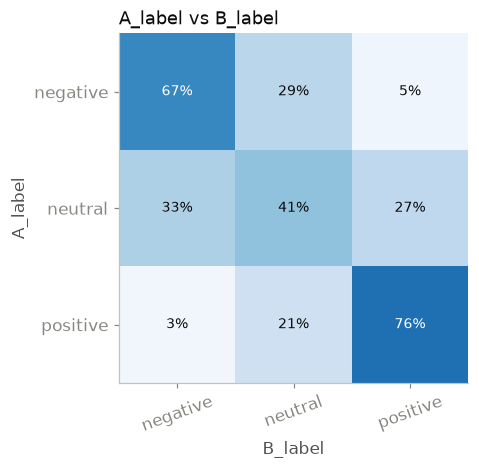

21:59:55 | INFO    | src.evaluation | Table saved: 03_crosstab_A_label_vs_C_label.csv
21:59:56 | INFO    | src.evaluation | Figure saved: 03_crosstab_A_label_vs_C_label.png


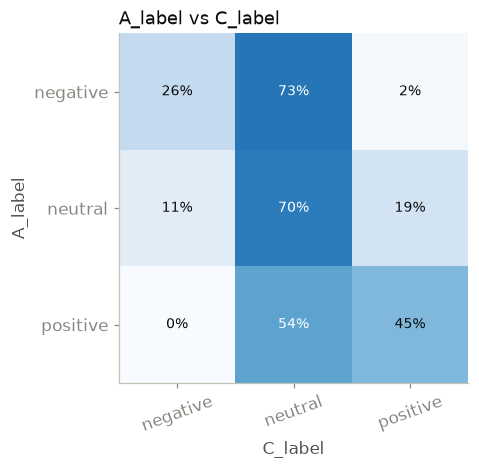

21:59:56 | INFO    | src.evaluation | Table saved: 03_crosstab_label_final_vs_score_cut_label.csv
21:59:57 | INFO    | src.evaluation | Figure saved: 03_crosstab_label_final_vs_score_cut_label.png


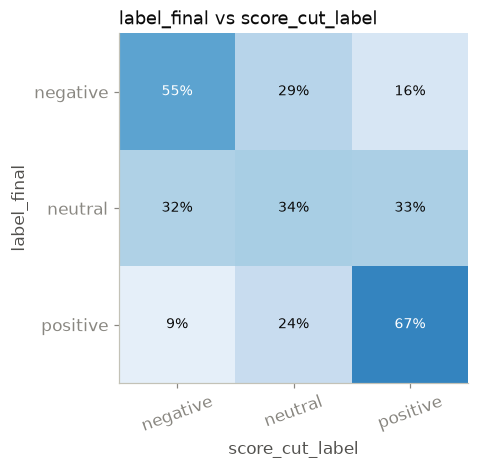

In [4]:
pairs = [("A_label", "B_label"), ("A_label", "C_label"), ("label_final", "score_cut_label")]
for col_a, col_b in pairs:
    if {col_a, col_b} <= set(data.columns):
        tab = lv.approach_crosstab(data[mask], col_a, col_b)
        name = f"03_crosstab_{col_a}_vs_{col_b}"
        ev.save_table(tab, name)
        lv.plot_agreement_matrix(tab, f"{col_a} vs {col_b}", xlabel=col_b, ylabel=col_a, save_as=name)
        plt.show()

## 3. Kapcsolat a vendégpontszámmal / Relation to the guest score

HU: Erős, de **nem tökéletes** kapcsolat a jó eredmény. A `neg_but_score_ge9` oszlop mutatja, hányszor panaszkodik a
szöveg magas pontszám mellett — ezt a pontszám-vágás nem látná.
EN: A strong but **imperfect** relation is the good outcome. `neg_but_score_ge9` shows how often the text complains
despite a high score — a score cut would miss this.

,spearman_rho,mean_guest_score_negative,mean_guest_score_neutral,mean_guest_score_positive,neg_but_score_ge9,pos_but_score_le6
approach,,,,,,
A,0.5633,7.2243,8.0446,8.9707,0.0046,0.0167
B,0.4299,7.4627,8.0914,9.1456,0.0094,0.0064
C,0.4742,7.4591,8.2664,9.2670,0.0046,0.0035
final,0.5385,7.4513,8.0553,9.1439,0.0084,0.0067


22:01:56 | INFO    | src.evaluation | Table saved: 03_guest_score_validity.csv
22:01:57 | INFO    | src.evaluation | Figure saved: 03_text_score_vs_guest_score.png


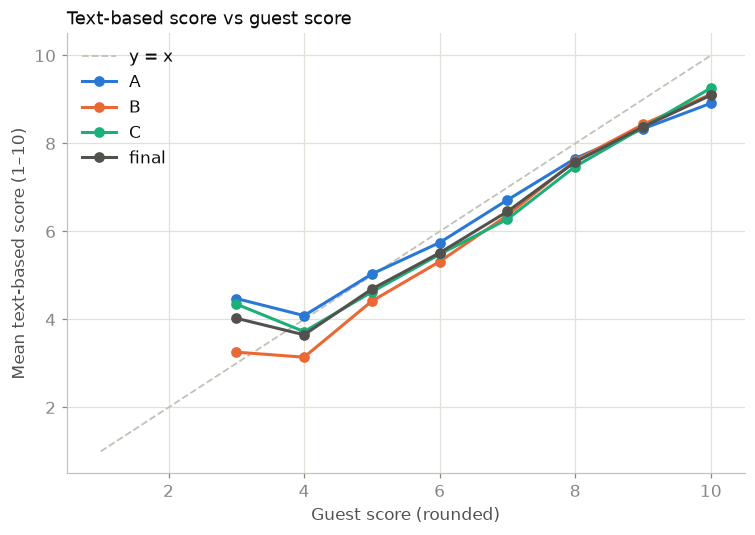

In [5]:
# HU: A végső címkét is "megközelítésként" kezeljük. / EN: The final label is treated as an "approach" too.
data["final_label"], data["final_score_cont"] = data["label_final"], data["score_cont_final"]
validity = lv.guest_score_validity(data, approaches + ["final"])
display(validity)
ev.save_table(validity, "03_guest_score_validity")
lv.plot_score_vs_guest(data, approaches + ["final"], save_as="03_text_score_vs_guest_score")
plt.show()

In [6]:
# HU: Ahol a szöveg és a pontszám nagyon eltér — olvasd el, és válassz idézeteket a dolgozatba.
# EN: Where text and score differ strongly — read them and pick quotes for the thesis.
disc = lv.text_score_discrepancies(data.reset_index(), min_gap=4, n_examples=12)
ev.save_table(disc, "03_text_score_discrepancies")
for _, r in disc.iterrows():
    print(f"[guest {r['score']:.0f} | text {r['score10_final']} | {r['label_final']}]  {r['text'][:230]}\n")

22:02:46 | INFO    | src.label_validation | Reviews with |text score − guest score| ≥ 4: 898 (4.49%)
22:02:46 | INFO    | src.evaluation | Table saved: 03_text_score_discrepancies.csv


[guest 9 | text 5 | neutral]  The room was really nice and comfortable and good value for money! Location is also nice with free private parking underground for the rooms. No lift could be used to go in the room and with a push chair and luggages it was diffic

[guest 7 | text 2 | negative]  breakfast n location Not enough storage n room size is small.

[guest 9 | text 5 | positive]  Location, ease of booking, price Bed was hard

[guest 7 | text 3 | negative]  Whirlpool tub

[guest 10 | text 6 | positive]  Great budget hotel for your money! Great location and friendly staff! The breakfast was very nice. Large buffet with choices. The staff was very kind and the location was perfect!!! Walking distance to the train station and everyt

[guest 10 | text 6 | neutral]  Great time great location. Like staying in amusement museum Stairs were a bit tricky

[guest 7 | text 3 | negative]  It would be a great hotel, but some of the staff are a disaster. The hotel's facilities and cleanliness were

## 4. Független próbák / Independent checks

In [7]:
for name in ["02_field_test", "02_approach_b_hrast_test"]:
    path = PATHS.tables / f"{name}.csv"
    if path.exists():
        print(f"=== {name} ===")
        display(pd.read_csv(path))
    else:
        print(f"{name}: not available (run notebook 02).")

=== 02_field_test ===


,approach,field,n,hit,neutral,opposite
0,A,review_negative,2000,0.4970,0.3450,0.1580
1,A,review_positive,2000,0.9475,0.0480,0.0045
2,C,review_negative,2000,0.6810,0.2125,0.1065
3,C,review_positive,2000,0.9460,0.0480,0.0060
4,B,review_negative,2000,0.7640,0.0995,0.1365
5,B,review_positive,2000,0.9780,0.0065,0.0155


=== 02_approach_b_hrast_test ===


,Unnamed: 0,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,HRAST test,0.9414,0.7731,0.7825,0.7776,0.9431,0.9414,0.9422


## 5. Kézi gold minta / Manual gold sample

HU: Az **egyetlen közvetlen pontosságmérés**. Lépések:
1. az alábbi cella exportálja a `data/annotation/gold_sample_to_annotate.csv` fájlt (csak szöveg — **vak** annotálás);
2. töltsd ki a `gold_label` (negative / neutral / positive) és a `gold_score` (1–10) oszlopot a `docs/ANNOTATION_GUIDE.md` szerint;
3. futtasd újra a cellát → összevetés minden forrással, a **pontszám-vágással együtt**.

EN: The **only direct accuracy measurement**. Export → annotate blind (`docs/ANNOTATION_GUIDE.md`) → re-run → comparison
with every source, **including the score cut**.

In [8]:
gold_file = PATHS.annotation / "gold_sample_to_annotate.csv"
if not gold_file.exists():
    lv.export_gold_sample(data.reset_index())
    print("Exported. Annotate it, then re-run this cell.")
else:
    gold = lv.load_gold()
    if len(gold) == 0:
        print("The gold file exists but has no valid gold_label yet.")
    else:
        score_cols = {**{a: f"{a}_score_cont" for a in approaches}, "final": "score_cont_final",
                      "score cut (reference)": "score"}
        gold_eval = lv.evaluate_on_gold(gold, data, SOURCES, score_cols)
        display(gold_eval)
        ev.save_table(gold_eval, "03_gold_evaluation")
        print("=> Set CFG.tie_breaker_approach in config.py to the best approach.")

22:05:09 | INFO    | src.label_validation | Gold sample exported: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\annotation\gold_sample_to_annotate.csv (400 reviews). Fill in gold_label (and gold_score).


Exported. Annotate it, then re-run this cell.
